# First leading the needed libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.image as mpimg
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score, pair_confusion_matrix
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from tqdm import tqdm

# Next loading the cleaned network flow data frame.

In [2]:
cleanDf = pd.read_csv(f'../data/processed/cicids2017_clean.csv')
cleanDf.head(5)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file,is_attack
0,49188,4,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0
1,49188,1,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0
2,49486,3,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0
3,49486,1,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0
4,88,609,7,4,484,414,233,0,69.142857,111.967895,...,0.0,0,0,0.0,0.0,0,0,BENIGN,Monday,0


# Next just to center this NB and its objective, this is the research question we are aiming to use k-means clustering to solve


Relationship / pattern
Do the four behavioral groups seen in the exploratory analysis hold up when individual flows are clustered, and are the overlapping pairs (Web Attack – Brute Force vs. XSS; Bot vs. BENIGN) separable at the flow level at all?

### And this is the figure that depicts the four behavior groups.

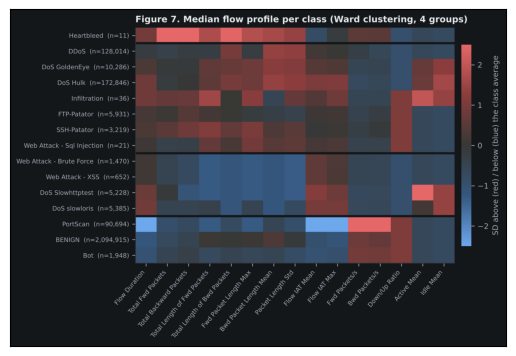

In [3]:
plt.imshow(mpimg.imread("../figures/rq3-class-profiles-dark.png"))
plt.xticks([])
plt.yticks([])
plt.show()

In [4]:
expected_groups = {"Heartbleed": "A",
         "DDoS": "B", "DoS GoldenEye": "B", "DoS Hulk": "B", "Infiltration": "B",
         "FTP-Patator": "B", "SSH-Patator": "B", "Web Attack - Sql Injection": "B",
         "Web Attack - Brute Force": "C", "Web Attack - XSS": "C",
         "DoS Slowhttptest": "C", "DoS slowloris": "C",
         "PortScan": "D", "BENIGN": "D", "Bot": "D"}


So if the initially derived four behavioral groups do, in fact, hold up. We would expect to see the following groups
- BENIGN, Bot, PortScan
- Dos Slowloris, DoS Slowhttptest, Web Attack - XSS , Web Attack - Brute Forice
- Web Attack - Sql Injection,SSH-Patator, FTP-Patator, Infiltration, DoS Hulk, DoS GoldenEye, DDoS
- Heartbleed

The dictionary will be used to compute the ARI score.

# Next we are going to standardize the columns and select only the behavior columns.

In [5]:
# BEHAVIORAL FEATURES ONLY: NO PORT, NO -1-CODED WINDOW FIELDS, NO 0/1 FLAGS
behav_cols = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets",
               "Total Length of Fwd Packets", "Total Length of Bwd Packets",
               "Fwd Packet Length Max", "Bwd Packet Length Mean", "Packet Length Std",
               "Flow IAT Mean", "Flow IAT Max", "Fwd Packets/s", "Bwd Packets/s",
               "Down/Up Ratio", "Active Mean", "Idle Mean"]

flow_clust_df = cleanDf[behav_cols]

# MEDIAN OF LOG10(1 + VALUE) PER CLASS: MEDIAN BECAUSE SKEWED, LOG BECAUSE MULTIPLICATIVE SCALES
flow_clust_df = np.log10(1 + flow_clust_df.clip(lower=0))
flow_clust_df.head(5)

,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Bwd Packet Length Mean,Packet Length Std,Flow IAT Mean,Flow IAT Max,Fwd Packets/s,Bwd Packets/s,Down/Up Ratio,Active Mean,Idle Mean
0,0.69897,0.477121,0.00000,1.113943,0.000000,0.845098,0.000000,0.00000,0.698970,0.698970,5.698971,0.000000,0.0,0.0,0.0
1,0.30103,0.477121,0.00000,1.113943,0.000000,0.845098,0.000000,0.00000,0.301030,0.301030,6.301030,0.000000,0.0,0.0,0.0
2,0.60206,0.477121,0.00000,1.113943,0.000000,0.845098,0.000000,0.00000,0.602060,0.602060,5.823909,0.000000,0.0,0.0,0.0
3,0.30103,0.477121,0.00000,1.113943,0.000000,0.845098,0.000000,0.00000,0.301030,0.301030,6.301030,0.000000,0.0,0.0,0.0
4,2.78533,0.903090,0.69897,2.685742,2.618048,2.369216,2.019116,2.03554,1.791691,2.582063,4.060519,3.817509,0.0,0.0,0.0


# Now before we apply the z score to the columns we'll test the rank correlation of each column. Note: the metric used here is Pearson.

The default correlation method is the pearson correlation coefficient. Which is formulated as follows:

\begin{align*}
\rho_{X,Y} = \frac{cov(X,Y)}{\sigma_X \sigma_Y}
\end{align*}

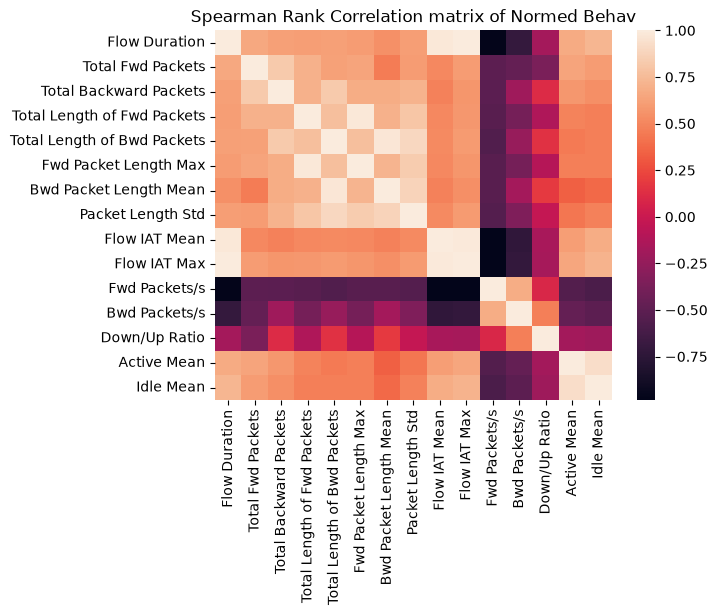

In [6]:
# Now just to check that no columns are spurious or to related we are going to examine the correlation real fast.
corr_test = flow_clust_df.corr()
sns.heatmap(data=corr_test)
plt.title("Spearman Rank Correlation matrix of Normed Behav")
plt.show()

From this it is pretty apparent that many of the columns are highly correlated, and therefore it is likely that they will essentially provide redundant information in the k-means distance calculation. However, to stay faithful to answering the original question posed by the research question we will begin the clustering experiments by keeping all 15 rows used to construct figure 7.

# Now Z Scoring the columns. Following along with the normalization steps used to create Figure 7.

In [7]:
# STANDARDIZE EACH FEATURE ACROSS CLASSES
if np.abs(1.0 - flow_clust_df['Flow Duration'].std()) < 0.001:
    print("It appears that z-score normalization was already performed.")
    display(flow_clust_df.head(5))
else:
    print("performing z-score normalization")
    flow_clust_df = (flow_clust_df - flow_clust_df.mean()) / flow_clust_df.std(ddof=0).replace(0, 1)
    display(flow_clust_df.head(5))

performing z-score normalization


,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Bwd Packet Length Mean,Packet Length Std,Flow IAT Mean,Flow IAT Max,Fwd Packets/s,Bwd Packets/s,Down/Up Ratio,Active Mean,Idle Mean
0,-1.716896,-0.442731,-1.350303,-0.659862,-1.414319,-0.802059,-1.508941,-1.380225,-1.724275,-1.725405,2.044125,-0.995745,-1.262621,-0.505268,-0.537404
1,-1.890385,-0.442731,-1.350303,-0.659862,-1.414319,-0.802059,-1.508941,-1.380225,-1.928348,-1.905228,2.382869,-0.995745,-1.262621,-0.505268,-0.537404
2,-1.759146,-0.442731,-1.350303,-0.659862,-1.414319,-0.802059,-1.508941,-1.380225,-1.773973,-1.769197,2.114421,-0.995745,-1.262621,-0.505268,-0.537404
3,-1.890385,-0.442731,-1.350303,-0.659862,-1.414319,-0.802059,-1.508941,-1.380225,-1.928348,-1.905228,2.382869,-0.995745,-1.262621,-0.505268,-0.537404
4,-0.807313,0.788323,0.402727,0.930716,0.410031,0.890069,0.336799,0.476024,-1.163903,-0.874466,1.122264,1.344518,-1.262621,-0.505268,-0.537404


# In response to the correlation matrix constructed above, we'll also define a function that selects only the least correlated columns up to a certain selected amount.

In [8]:
def construct_greedy_cols(target_col_amt,df,seed_col='Flow Duration',cor_thresh=0.8):
    # First construct the initial seed and the correlation comparison.
    least_corr_cols = set(seed_col)
    corr_matx = df.corr(method='pearson').abs()
    chosen = [seed_col]

    while len(chosen) < target_col_amt:
        candidates = [c for c in corr_matx.columns if c not in chosen]
        block = corr_matx.loc[candidates, chosen]

        # Eliminate candidates where they are correlated above the desired threshold
        # to the already chosen columns.
        eligible = block[block.max(axis=1) < cor_thresh]
        if eligible.empty:
            break   # RAN OUT OF COLUMNS THAT PASS

        chosen.append(eligible.mean(axis=1).idxmin())

    return chosen
        
# As a example of this working.
construct_greedy_cols(3,flow_clust_df)
    

['Flow Duration', 'Down/Up Ratio', 'Packet Length Std']

# Now that we got all the setup completed the next thing is making a function that will actually do the clustering and report the relivant numerical values.

In [9]:
def balance_df(df):
    if 'Label' not in df.columns:
        return None
    
    df_with_lab = df.copy()
    #df_with_lab["Label"] = df['Label']

    balance_df = (df_with_lab
            .sample(frac=1, random_state=5502)   # shuffle every row to take a fair sample of each class.
            .groupby("Label") 
            .head(2_000)).reset_index(drop=True) # Now actually take the samples.

    return balance_df

# SO HERE I'M ASSUNMING THE SPLIT DF has just the Label and assigned cluster columns.
def calc_entropy(split_df):
    if 'Label' not in split_df.columns or 'ass_clust' not in split_df.columns:
        return None


    poss_labs = split_df['Label'].unique()
    num_classes = len(poss_labs)
    clusts = split_df['ass_clust'].unique()
    entropy_dict = {}
    def _calc_log_change_base(p):
        return np.log(p) / np.log(num_classes)

    for clust_num in clusts:
        clust_entries = split_df[split_df['ass_clust'] == clust_num]
        clust_size = clust_entries.shape[0]
        #print(clust_size)
        ent_sum = 0
        

        for lab in poss_labs:
            num_with_lab = clust_entries[clust_entries['Label'] == lab].shape[0]

            if num_with_lab != 0:
                p = num_with_lab / clust_size
                #print((_calc_log_change_base(p),p))
                
                ent_sum += -1 * p * _calc_log_change_base(p)
        #print(ent_sum)
        entropy_dict[clust_num] = ent_sum

    return entropy_dict

    

def perform_clustering_exp(clust_df,expected_groups,scatter_plot_hues,n_clust=4,n_init=10,random_state=5502,perform_pca=False,show_pcm_vis=True,show_cross_tab=True):
    # First we'll try to match the expected groups with the given df.
    group = clust_df['Label'].map(expected_groups)   
    if not group.notna().all() or 'Label' not in clust_df.columns:
        return None

    # Next we'll run k means.
    kmeans_alg = KMeans(n_clusters=n_clust,n_init=n_init,random_state=random_state)
    test_res = kmeans_alg.fit(clust_df.drop(columns=['Label']))
    # Doing this to get rid of a warning
    clust_centers = pd.DataFrame(kmeans_alg.cluster_centers_, columns=kmeans_alg.feature_names_in_)
    # We are also going to compute the silhouette to use later for k tuning.
    #The sample size here is a moderate but not totally sluggish portion of the orignal df to compute.
    sil_score = silhouette_score(clust_df.drop(columns=['Label']), kmeans_alg.labels_, sample_size=10000, random_state=random_state)

    # Now we are going to calculate the entropy for each cluster. First 
    # we're going to create a df specifically setup for the entropy calc.
    split_df = clust_df[['Label']].copy()
    split_df['ass_clust'] = test_res.labels_


    
    # Now get the ari score to see how well the groups that we theorized aligned with what
    # the clustering reality actually was.
    ari = adjusted_rand_score(group, test_res.labels_)
    if show_pcm_vis:
        # Also get this confusion matrix to visualize how well the expected groups aligned with reality.
        pcm = pair_confusion_matrix(group, test_res.labels_)

        # Change the PCM to percentages and make the labels meaningful for the matrix visual.
        pcm_pct = pcm / pcm.sum(axis=1, keepdims=True) * 100
        pcm_mat = pd.DataFrame(pcm_pct,columns=['Different Cluster','Same Cluster'])
        pcm_mat.index = ['Different Groups','Same Groups']

        # Show the matrix visual.
        sns.heatmap(data=pcm_mat,annot=True,fmt='.2f',cmap="viridis")
        plt.title(f"Heatmap of Expected Clustering Confusion Matrix\n with ARI {ari:.3f}")
        plt.show()


    
    
    

    # Now if the user want to see the PCA scatter plot we will show that as well.
    if perform_pca:
        
                
        # Now use the above function to calculate the entropy for each split.
        entropy_dict = calc_entropy(split_df)

        pca = PCA(n_components=2,random_state=random_state)
        dim_red_pts = pca.fit_transform(clust_df.drop(columns=['Label']))
        clust_cents_red = pca.transform(clust_centers)

        

        

        plt.figure(figsize=(16, 10))
        ax = sns.scatterplot(x=dim_red_pts[:,0],y=dim_red_pts[:,1],hue=kmeans_alg.labels_.astype(str),palette=scatter_plot_hues,hue_order=[str(idx) for idx in range(0,n_clust)])
        plt.title(f"KMeans Clustering Results. Visualized Using PCA. With Per Cluster Entropy")
        plt.xlabel(f"X1 Explained Var: {pca.explained_variance_ratio_[0]:.3f}")
        plt.ylabel(f"X2 Explained Var: {pca.explained_variance_ratio_[1]:.3f}")

        for clust_num, (x, y) in enumerate(clust_cents_red):
            ax.scatter(x, y, marker="X", s=120, c="black")
            plt.annotate(f"{clust_num} H = {entropy_dict[clust_num]:.2f}", (x, y),
                    xytext=(6, 6), textcoords="offset points", fontsize=9, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
        ax.legend(title="Cluster", markerscale=3)

        plt.show()


    if show_cross_tab:
        # Finally show the share that each class ended up in each cluster
        class_dispertions = pd.crosstab(split_df["Label"], split_df["ass_clust"], normalize="index")
        class_freq = pd.crosstab(split_df["Label"], split_df["ass_clust"])

        # Now we are going to do a heatmap for the cross tab for better visualization.
        plt.figure(figsize=(18, 8))
        sns.heatmap(class_dispertions,annot=True,fmt='.2f',cmap="viridis")
        plt.title("Class Dispersion Across Clusters (each row sums to 1)")
        plt.show()
        
        most_frequent_per_clust = pd.DataFrame({
            "Most Frequent In Cluster": class_freq.idxmax(),
            "Share of Cluster": (class_freq.max() / class_freq.sum()).round(2),
        })
        display(most_frequent_per_clust)

    # Normalize the inertia down to a more intelligible value.
    possible_sum_squares = clust_df.shape[0]*(len(clust_df.columns)-1)
    # Finally return some key metrics.
    return((kmeans_alg.inertia_/possible_sum_squares),sil_score,ari,kmeans_alg.labels_)
    
    

## Now before we proceed any further it is helpful to actually write down and note what all the formulas we are using mean.

The formulas in use can be broken down into the following categories.

#### First, is the formulas used to directly measure the performance of the clustering itself to find the best k value independent off what Figure 7 originally hypothesized for the grouping.
For this group I used this site to formulate these explanations 
(https://medium.com/@jeffzyme understanding-inertia-distortion-and-silhouette-scores-and-their-differences-key-metrics-for-458fe28ce2aa)

So first inertia:

\begin{align*}
\text{Inertia} = \sum_{i=1}^{k}\sum_{x \in C_i} ||x - \mu_i||^2
\end{align*}

Where $k$ represents the number of clusters, $x$ is a data point in cluster $C_i$, and $\mu_i$ is the centroid of the cluster $C_i$. This represents the sum of each point's squared distance to its centroid. However, a key aspect of this formula is that adding more clusters will, in principle, decrease the inertia in most cases. So this measure alone does not tell us the most optimal k.

The next measure in this group to find the optimal k value is the silhouette score:

So for an individual point $x$ 

\begin{align*}
s(x) = \frac{b-a}{\max(a,b)}
\end{align*}

Where $b$ is the average distance of point $x$ to points in the nearest neighboring cluster. And $a$ is the average distance of point $x$ to points in the same cluster.
The overall silhouette score is then:

\begin{align*}
\text{Silhouette} = \frac{1}{n} \sum_{i=1}^n s(x_i)
\end{align*}

So overall, when the Silhouette score approaches 1 then this means that our clusters are well separated, when the value approaches 0 this means that the clusters are not as well separated and are beginning to overlap. And when the score approaches -1 this suggests badly assigned clusters; this case is far less likely in reality.

#### Second, we ask how well the assigned groups align with what we hypothesized in Figure 7.

The measure used to answer this question is the ARI, or Adjusted Rand Index. Which to explain this measure it helps to first realize the contingency table or pair confusion matrix this measure can be formulated in the context of. So for the PCM, if we have a hypothesized grouping C2 and the actual grouping k-means computed C1, then the PCM contingency table looks as follows:

For all pairs of points

|  | K-Means (C1) Clustering Different Clusters | K-Means (C1) Clustering Same Clusters |
| --- | --- |  --- |
Hypothesized (C2) Different Groups | TN | FP |
Hypothesized (C2) Same Groups | FN | TP |

Then ARI is:
\begin{align*}
\text{ARI} = \frac{2(TP\cdot TN-FN\cdot FP)}{(TP+FN)(FN+TN)+(TP+FP)(FP+TN)}
\end{align*}

To understand what this fraction represents it helps to look at the extremes. So if our hypothesized grouping totally agrees with the actual k-means result then we get this:
\begin{align*}
\text{ARI} &= \frac{2(TP\cdot TN-0 \cdot 0)}{(TP+0)(0+TN)+(TP+0)(0+TN)} \\
           &= \frac{2(TP\cdot TN)}{(TP\cdot TN)+(TP\cdot TN)} \\
           &= \frac{2(TP\cdot TN)}{2(TP\cdot TN)} \\
           &= 1
\end{align*}

Now, the other extreme that matters is when the two groupings are completely unrelated, meaning C1 clusters have nothing to do with the C2 groups. In that case ARI is about 0. If our two partitions C1 and C2 are totally unrelated, and we call $TP \cdot TN$ the "Good Diagonal" and $FN \cdot FP$ the "Bad Diagonal", we would expect a nearly equivalent spread between the good and bad diagonals so $TP\cdot TN-FN\cdot FP \approx 0$. The denominator depends only on the number of pairs each partition C1 and C2 put together and apart, not on how well the two partitions line up with each other. So, the denominator stays a fixed non-zero number. So in this case, ARI goes toward Zero. This is the same idea as $\frac{0}{x} = 0$.

Finally, the negative case is when C1 and C2 systematically disagree which would result in a negative ARI score.


In [10]:
flow_clust_with_lab = flow_clust_df.copy()
flow_clust_with_lab["Label"] = cleanDf["Label"]

# The question now is without class balancing how do our results look. Also, using all features here.

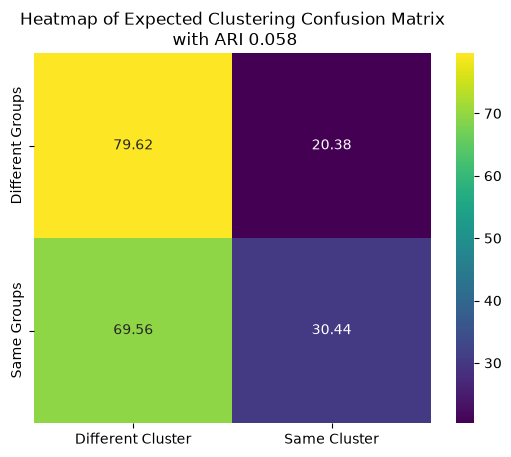

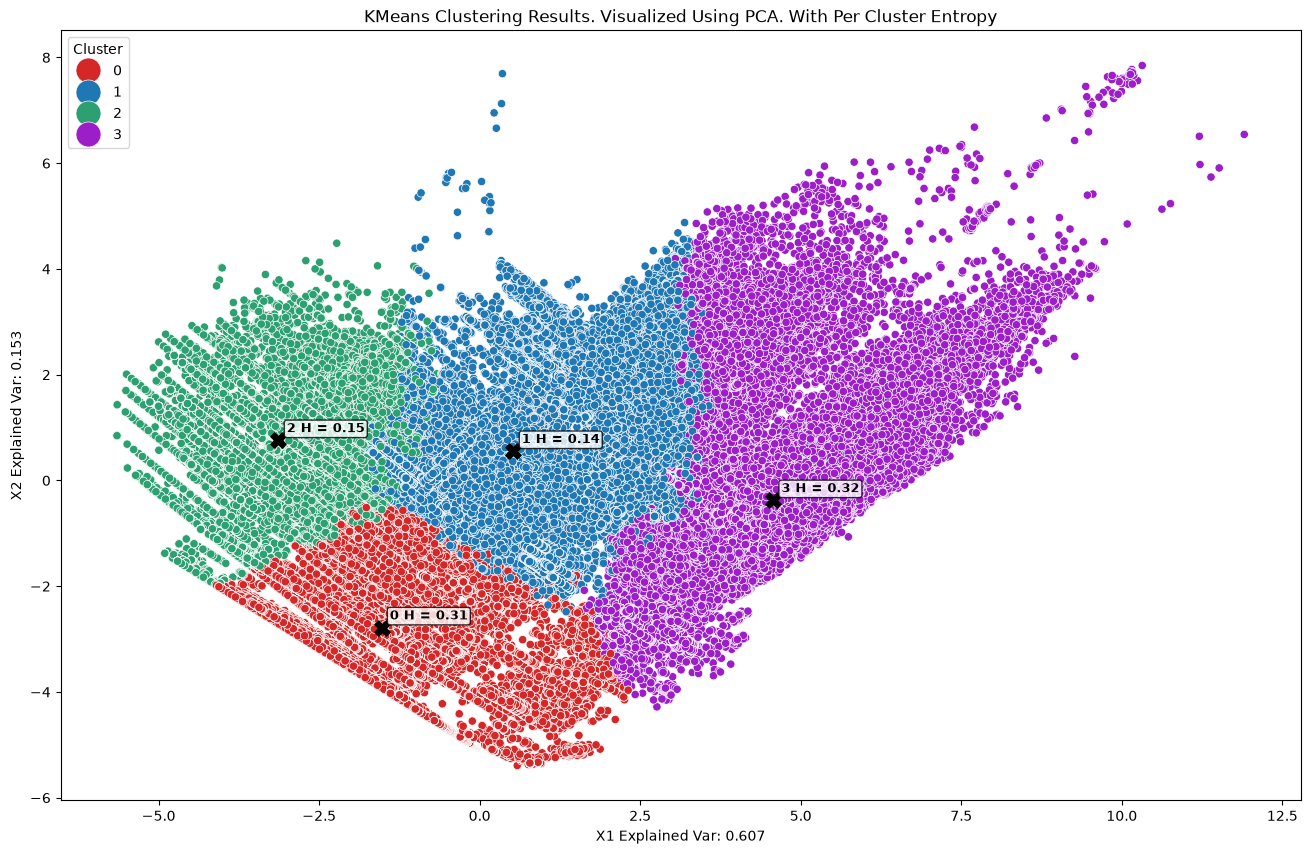

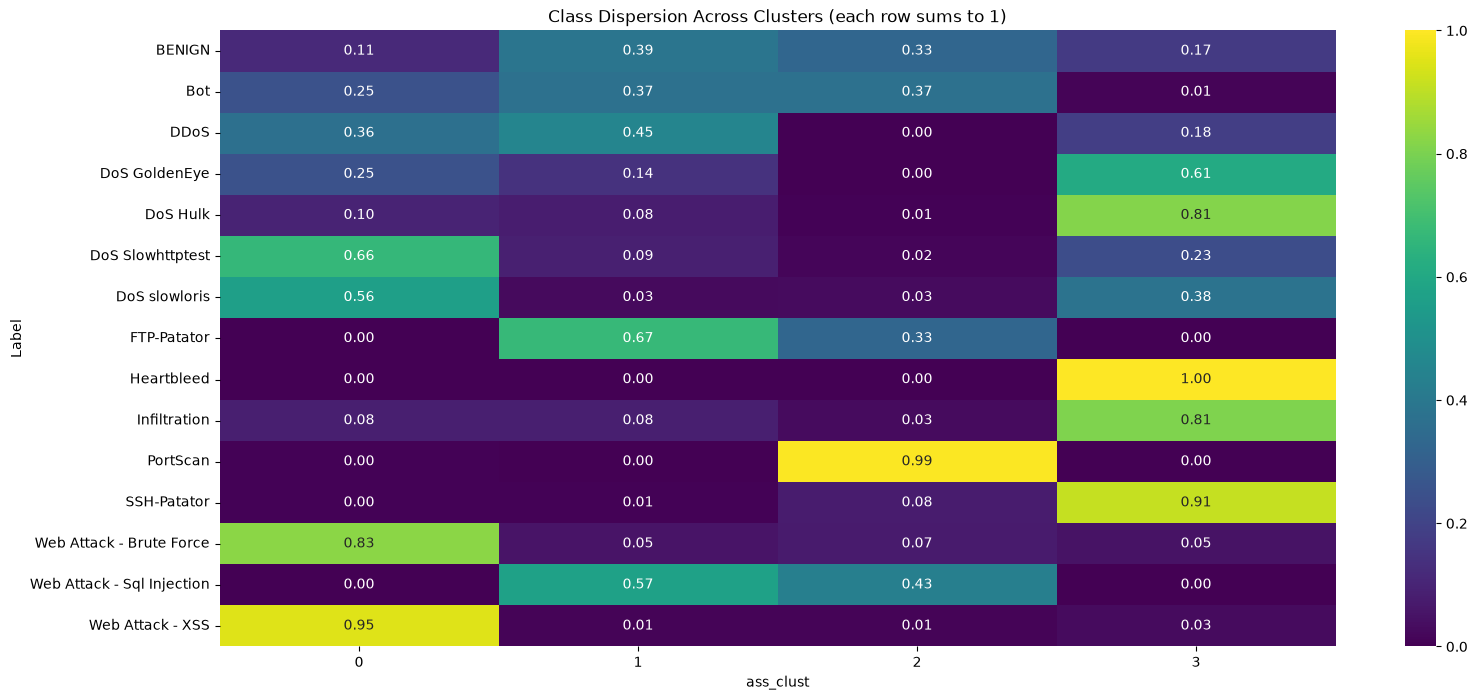

,Most Frequent In Cluster,Share of Cluster
ass_clust,,
0,BENIGN,0.76
1,BENIGN,0.91
2,BENIGN,0.88
3,BENIGN,0.67


The Silhouette score for k = 4 was 0.387


In [11]:
hues_dict = {"0": "#d62728", "1": "#1f77b4", "2": "#2ca070", "3": "#9c1ec9"}
_, sil_score ,_, _ = perform_clustering_exp(flow_clust_with_lab,expected_groups,hues_dict,perform_pca=True)
print(f"The Silhouette score for k = 4 was {sil_score:.3f}")

So, a few things to note here.

First, our ARI score is pretty low at $0.05776014943087266$. So initially this ARI score would suggest that well our expected groupings and the observed ones aren't totally unrelated, they are not in much alignment at all. We can also see from the top confusion matrix that our TN rate is pretty high at %$79.62$. But our FN rate is also pretty high at %$69.56$. In comparison to these two our TP rate is pretty low at %$30.44$.

However, the reason for this pour alignment becomes far clearer once we look at the class distribution across clusters. Our BENIGN traffic is very dispersed thought all the clusters with it making up more than half of every cluster. For the attack classes they align better with the hypothesized groups. For cluster three some of the attack classes that appear the most frequently are DoS GoldenEye/Hulk, Infiltration, and SSH-Patator; with percentages of class records in cluster 3 being $61\%, 81\%, 81\%, \text{ and } 91\%$, respectively.  So our pour ARI score here is more an artifact of the extreme class imbalance then any definitive indication that our hypothesized groups do not agree with k-means clustering. It is also intriguing that $100\%$ of Heartbleed attack records land in cluster 3. This is something worth keeping an eye on when we balance the classes and perform clustering again.

Also, the entropy or chaos of each cluster is pretty low, but that is mostly because BENIGN traffic dominates so much of each cluster.

# Now using balanced classes to see how well the four clusters align with the theorized ones and how the seperation is looking. This is done on the full feature set.

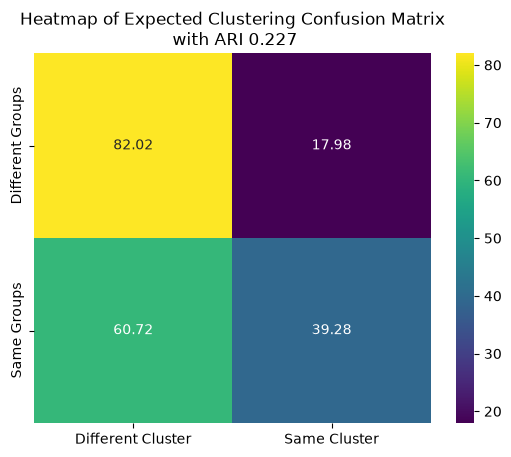

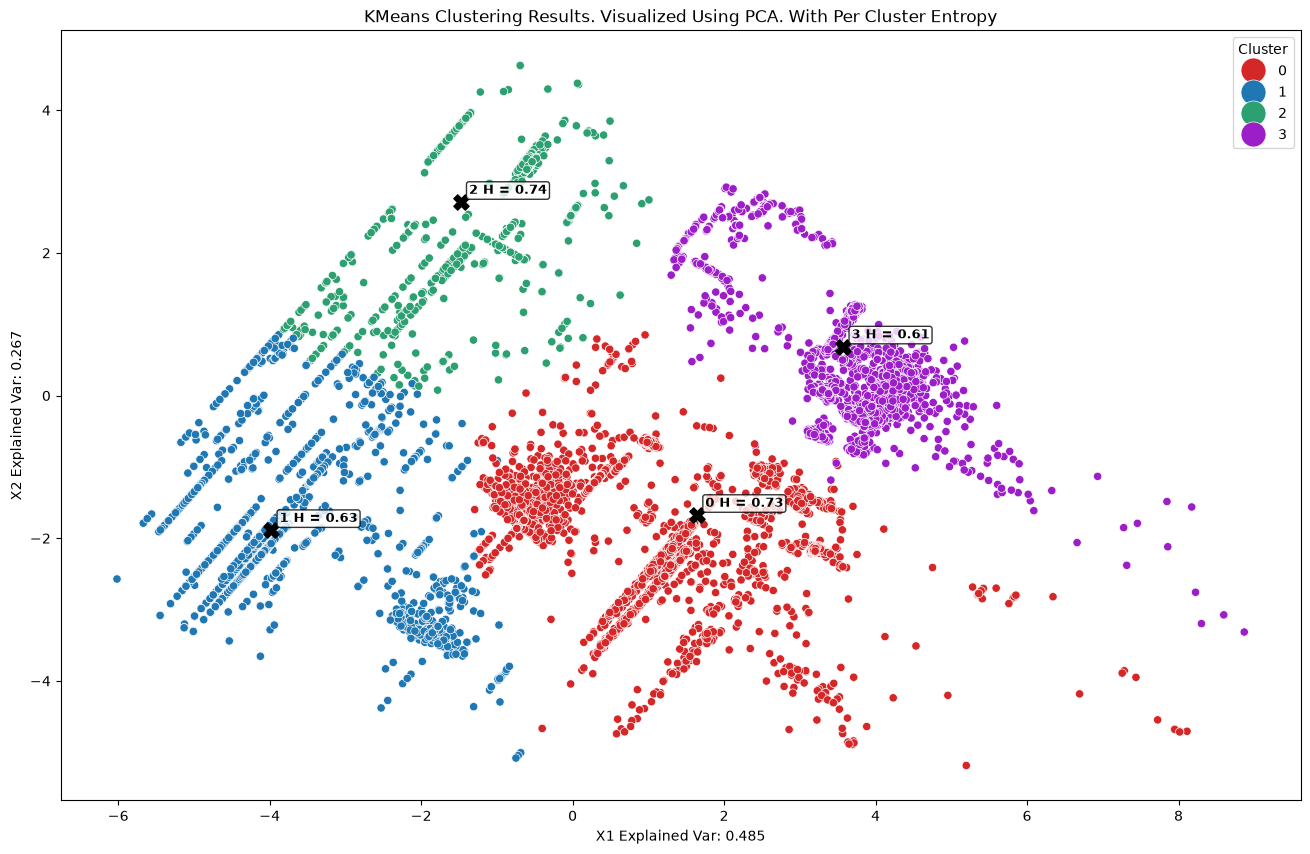

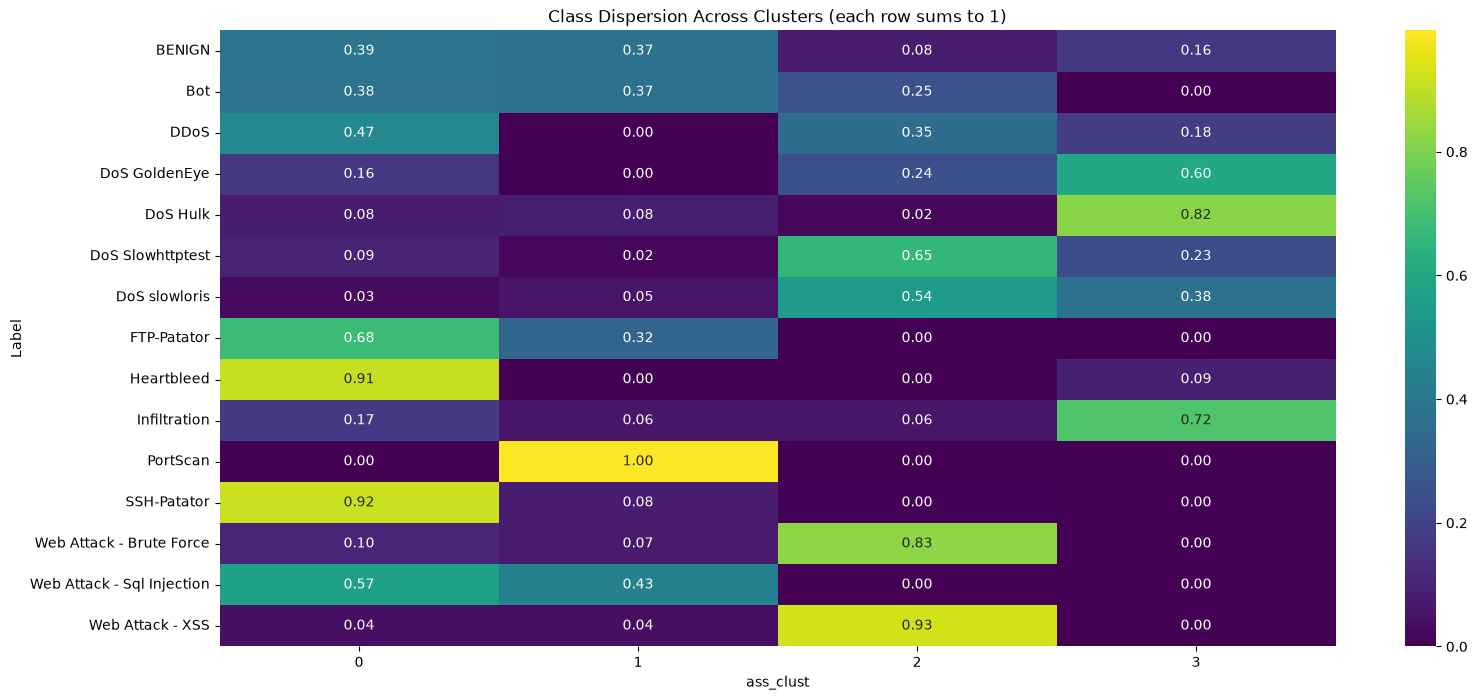

,Most Frequent In Cluster,Share of Cluster
ass_clust,,
0,SSH-Patator,0.28
1,PortScan,0.42
2,DoS Slowhttptest,0.21
3,DoS Hulk,0.34


The Silhouette score for k = 4 was 0.467


In [12]:
# First balance the classes.
hues_dict = {"0": "#d62728", "1": "#1f77b4", "2": "#2ca070", "3": "#9c1ec9"}
balanced_df = balance_df(flow_clust_with_lab)
# Verify that the balanced df is not none.
if balance_df is None:
    print("Balancing the DF failed!!")
else:
    _, sil_score ,_, _ = perform_clustering_exp(balanced_df,expected_groups,hues_dict,perform_pca=True)
    print(f"The Silhouette score for k = 4 was {sil_score:.3f}")

So balancing the classes noticeably improved our ARI score to $0.227$. The balanced classes also result in a higher TN rate of $82.02\%$ and a lower FN rate of $60.72\%$. The TP rate also increases to $39.28\%$; while the FP rate drops to $17.98\%$. So overall, the balanced classes bring noticeably improved alignment with the hypothesized groupings and the observed ones in clustering. Additionally, classes like Web Attack - Brute Force and Web Attack - XSS still frequently occur in the same cluster, with the percentage of their records landing in cluster two being $83\%$ and $93\%$, respectively. Heartbleed also remains in the same cluster as SSH-Patator and not in its own separate group as originally hypothesized.

The entropy rose for each cluster here predominantly due to BENIGN no longer overwhelming every cluster. With the higher entropy values, classes within clusters are largely mixed, supported by the fact that cluster 1's most predominant class (PortScan) only makes up $42\%$ of all the records in that cluster. So there isn't really any cluster that is dominated by a single class. So at least at k = 4, Heartbleed does not get its own cluster, although with only 11 records, it is highly unlikely for Heartbleed to get its own cluster. With the lowest entropy being cluster three with $0.61$, all this tells us is that no class was distinct enough with k=4 to get its own cluster. 

The Silhouette score has also gotten considerably better at $0.467$. So while our clusters are starting to cary signal the signal is still pretty weak.

So overall, while we are beginning to see more alignment between the hypothesized and actually formed clusters with balanced classes, we have not yet reached a point where these groups cary a hugely meaningful signal.

# What's next?

One possible question after observing low ARI scores is this: does k = 4 match the data’s natural structure at all? Is there a k where the data separates more cleanly (measured by silhouette), and how does that structure relate to the originally hypothesized groups?

# Now the next thing we are going to do is use the greedy column selection tool to drop redundant columns.

The reason we are performing this column selection process first is to give our k searching method the best possible chance to find the best possible k.

In [13]:
non_redudant_cols = construct_greedy_cols(15,flow_clust_with_lab.drop(columns=['Label']))
non_redudant_cols.append('Label')
non_redudant_cols

['Flow Duration',
 'Down/Up Ratio',
 'Packet Length Std',
 'Active Mean',
 'Bwd Packets/s',
 'Total Backward Packets',
 'Label']

Now actually select those most independent columns.

In [14]:
reduced_cols_clust_df = flow_clust_with_lab[non_redudant_cols]
reduced_cols_clust_df.head(5)

,Flow Duration,Down/Up Ratio,Packet Length Std,Active Mean,Bwd Packets/s,Total Backward Packets,Label
0,-1.716896,-1.262621,-1.380225,-0.505268,-0.995745,-1.350303,BENIGN
1,-1.890385,-1.262621,-1.380225,-0.505268,-0.995745,-1.350303,BENIGN
2,-1.759146,-1.262621,-1.380225,-0.505268,-0.995745,-1.350303,BENIGN
3,-1.890385,-1.262621,-1.380225,-0.505268,-0.995745,-1.350303,BENIGN
4,-0.807313,-1.262621,0.476024,-0.505268,1.344518,0.402727,BENIGN


So this will be the set of features that we use in finding the most optimal k.

# Performing the K value tuning on the BALANCED dataset.

Now this part attempts to answer the question posed earlier in the notebook: "Is there a k where the data separates more cleanly (measured by silhouette)". Inertia is also used here to see when the sum of each point squared difference within clusters stops dramatically decreasing. At this point the ARI value is less of a focus as the increased k size makes the value and contingency table less of a direct comparison.

In [15]:
# First define the required color paldet though we will not use it here.
hues_dict = {"0": "#d62728", "1": "#1f77b4", "2": "#2ca070", "3": "#9c1ec9","4": "#E5C2D0"}

balanced_df = balance_df(reduced_cols_clust_df)
scores = []
k_searches = np.array(range(2,70))
# Verify that the balanced df is not none.
if balance_df is None:
    print("Balancing the DF failed!!")
else:
    for k in tqdm(k_searches):
        intertia_curr, sil_score_curr, ari_curr, _ = perform_clustering_exp(balanced_df,expected_groups,hues_dict,perform_pca=False,show_pcm_vis=False,show_cross_tab=False,n_clust=k)
        scores.append([intertia_curr, sil_score_curr, ari_curr])

scores = np.array(scores)

100%|██████████| 68/68 [01:04<00:00,  1.06it/s]


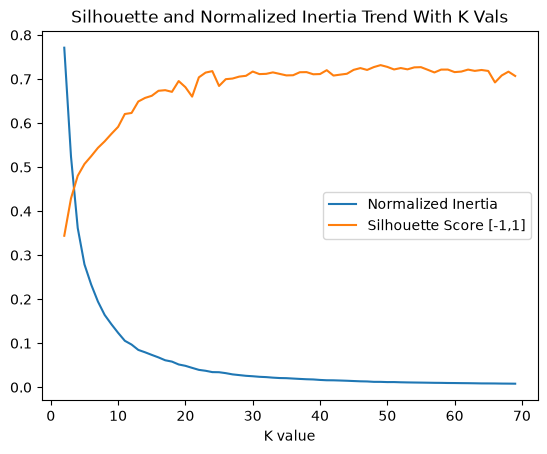

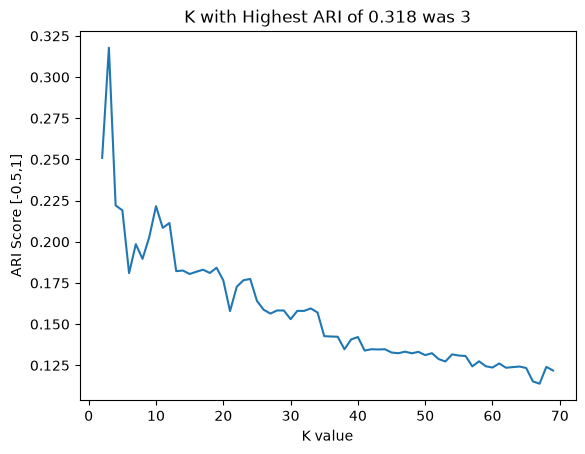

In [16]:
plt.plot(k_searches ,(scores[:,0]),label="Normalized Inertia")
plt.plot(k_searches , scores[:,1],label="Silhouette Score [-1,1]")
plt.xlabel("K value")
plt.title("Silhouette and Normalized Inertia Trend With K Vals")
plt.legend()
plt.show()

sns.lineplot(x = k_searches , y=scores[:,2])
plt.title(f"K with Highest ARI of {scores[:,2].max():.3f} was {k_searches[scores[:,2].argmax()]}")
plt.xlabel("K value")
plt.ylabel("ARI Score [-0.5,1]")
plt.show()

So after performing the k-tuning above, we see that the inertia curve begins to flatten out around k= 10 and has become nearly flat by k = 20. The silhouette curve begins to reach a point of diminishing returns starting at about k = 20. So a k that gains meaningful signal between the clusters could be in the 20-25 range, where the first signs of the curve leveling begin. For the sake of the cluster visual and the Class Dispersion Heatmap still being readable, we'll use k = 22 to visually examine the clustering with this value. While this k value is much larger than the original four groups, it remains to be seen if those finer clusters are smaller subgroups of the originally observed groupings.

# Now examining the serperation and performance with 22 clusters, doing this partially because it is still able to be visualized in the scatter plot as well.

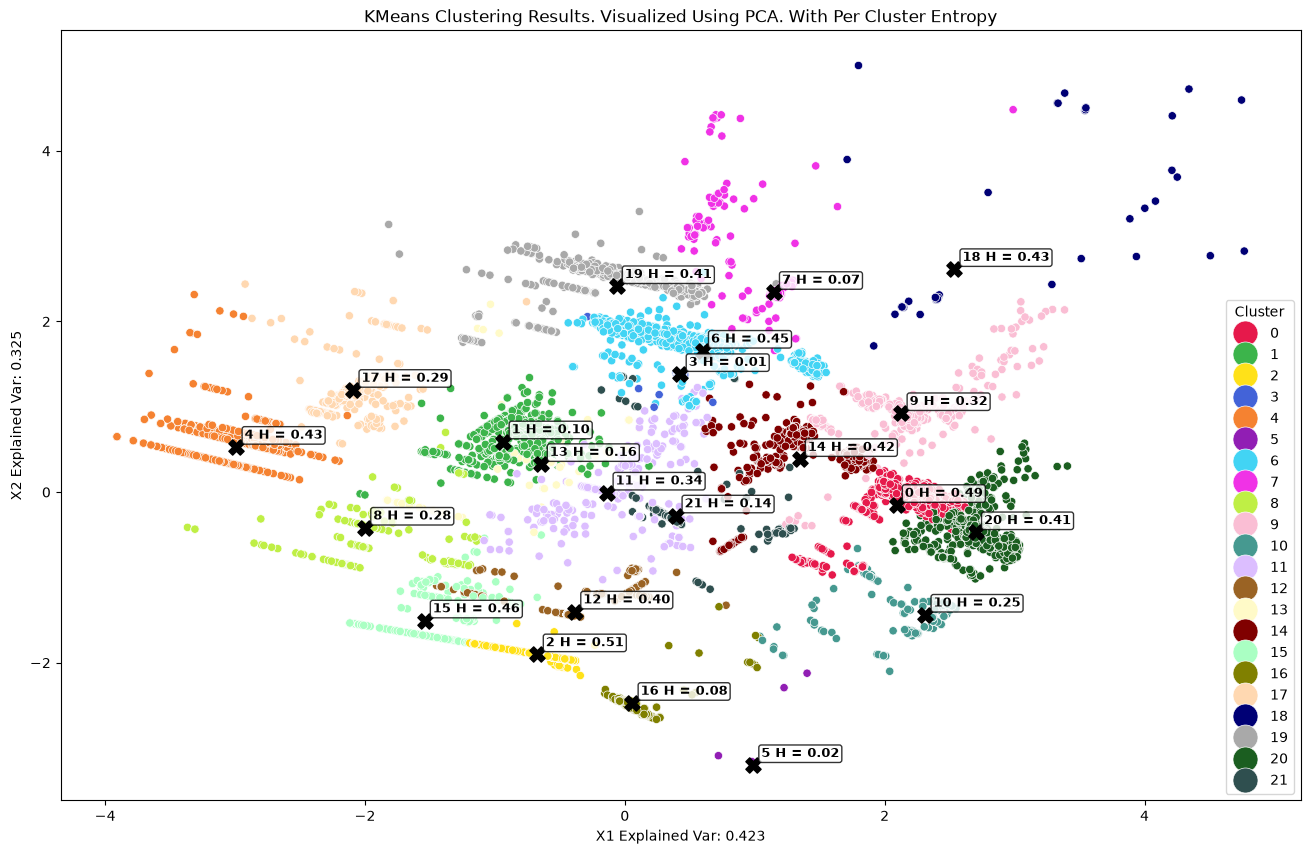

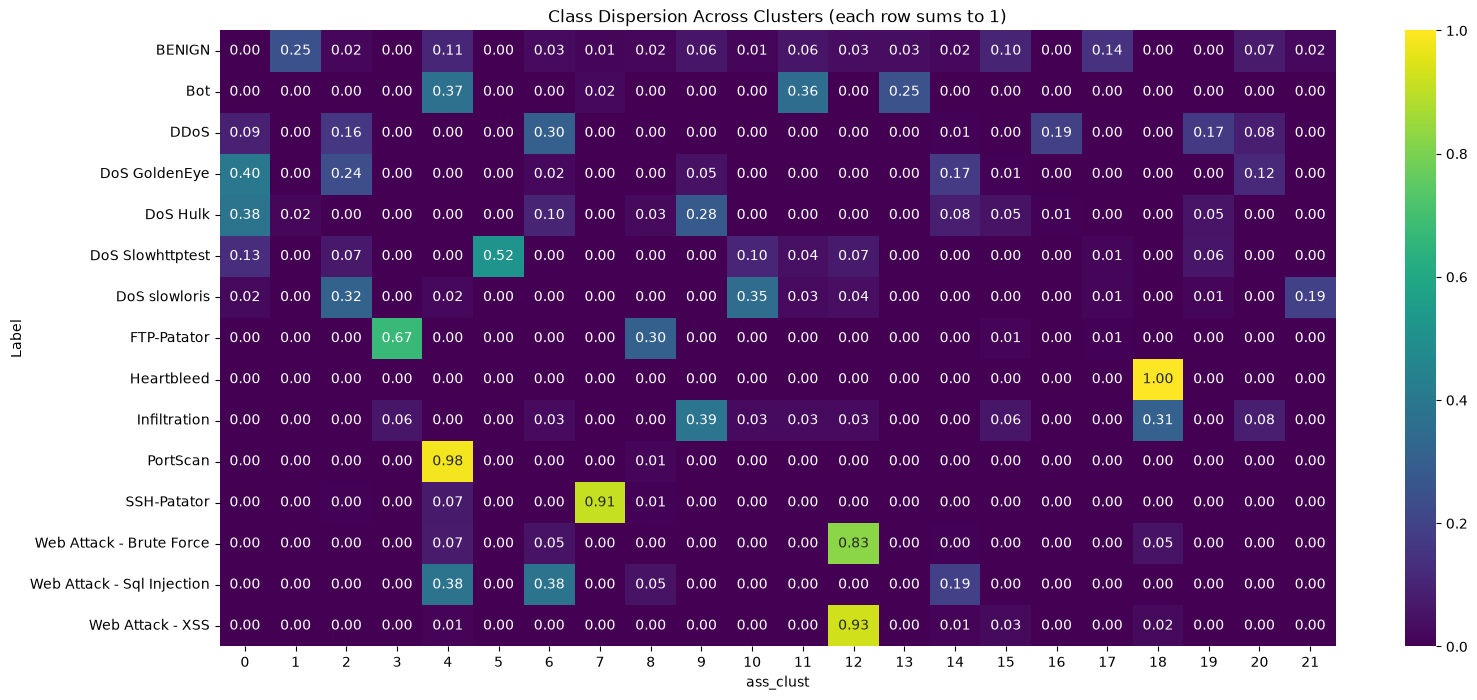

,Most Frequent In Cluster,Share of Cluster
ass_clust,,
0,DoS GoldenEye,0.39
1,BENIGN,0.93
2,DoS slowloris,0.39
3,FTP-Patator,1.00
4,PortScan,0.61
5,DoS Slowhttptest,0.99
6,DDoS,0.60
7,SSH-Patator,0.96
8,FTP-Patator,0.81


The Silhouette score for k = 22 was 0.704


In [37]:
balanced_df = balance_df(reduced_cols_clust_df)
# Verify that the balanced df is not none.
if balance_df is None:
    print("Balancing the DF failed!!")
else:
    hues_dict = {
    "0": "#e6194B", "1": "#3cb44b", "2": "#ffe119", "3": "#4363d8", "4": "#f58231",
    "5": "#911eb4", "6": "#42d4f4", "7": "#f032e6", "8": "#bfef45", "9": "#fabed4",
    "10": "#469990", "11": "#dcbeff", "12": "#9A6324", "13": "#fffac8", "14": "#800000",
    "15": "#aaffc3", "16": "#808000", "17": "#ffd8b1", "18": "#000075", "19": "#a9a9a9",
    "20": "#1b5e20", "21": "#2f4f4f"
    }

    _, sil_score ,_,_ = perform_clustering_exp(balanced_df,expected_groups,hues_dict,perform_pca=True,show_pcm_vis=False,n_clust=22)
    print(f"The Silhouette score for k = 22 was {sil_score:.3f}")

So, as was expected, at k = 22 we see a noticeable improvement in the Silhouette score to $0.704$. So now our clusters are beginning to have meaningful signal. Furthermore, we have clusters like cluster 16 with a super low entropy of $0.08$. So the increased k did have a meaningful effect compared to a direct mapping of k=4 original groups. But do these finer groups still group the originally hypothesized pair of classes together? 

Classes that appear together in Figure 7 and in the finer clustering include Web Attack – Brute Force and XSS (cluster 12), DoS GoldenEye and Hulk (cluster 0), and PortScan and Bot (cluster 4). It should be noted with these pair agreements however, that many of the classes also occur in multiple clusters. Heartbleed occurs only in cluster 18, which it shares largely with Web Attack - Brute Force. $83\%$ of Brute Force records are in cluster 12 while only $5\%$ of Brute Force records are in cluster 18. So while not every pair of classes occur every time together in the manner originally hypothesized, many of them do.

One more interesting point to drill in on is with DDoS. This class takes up $96\%$ of cluster 16 and also $60\%$ of cluster 6. It is the most concentrated in cluster 6, with $30\%$ of its records landing here. Also in cluster 6 is Web Attack - Sql Injection ($38\%$ of its records are in cluster 6 and $38\%$ are in cluster 4). Web Attack - Sql Injection and DDoS were, in fact, together in the original grouping in Figure 7, so their co-occurrence in cluster 6 is in alignment with the original hypothesis. But Web Attack - Sql Injection being in cluster 4 with PortScan is not in alignment with the original hypothesis.

The far more interesting thing here, though, is that even a single class, like DDoS, has points separated by distinct clusters with a visibly noticeable distance on the PCA scatter plot between the multiple clusters that single class occupies.

# Now visualizing the median transformed value for each cluster for each feature.

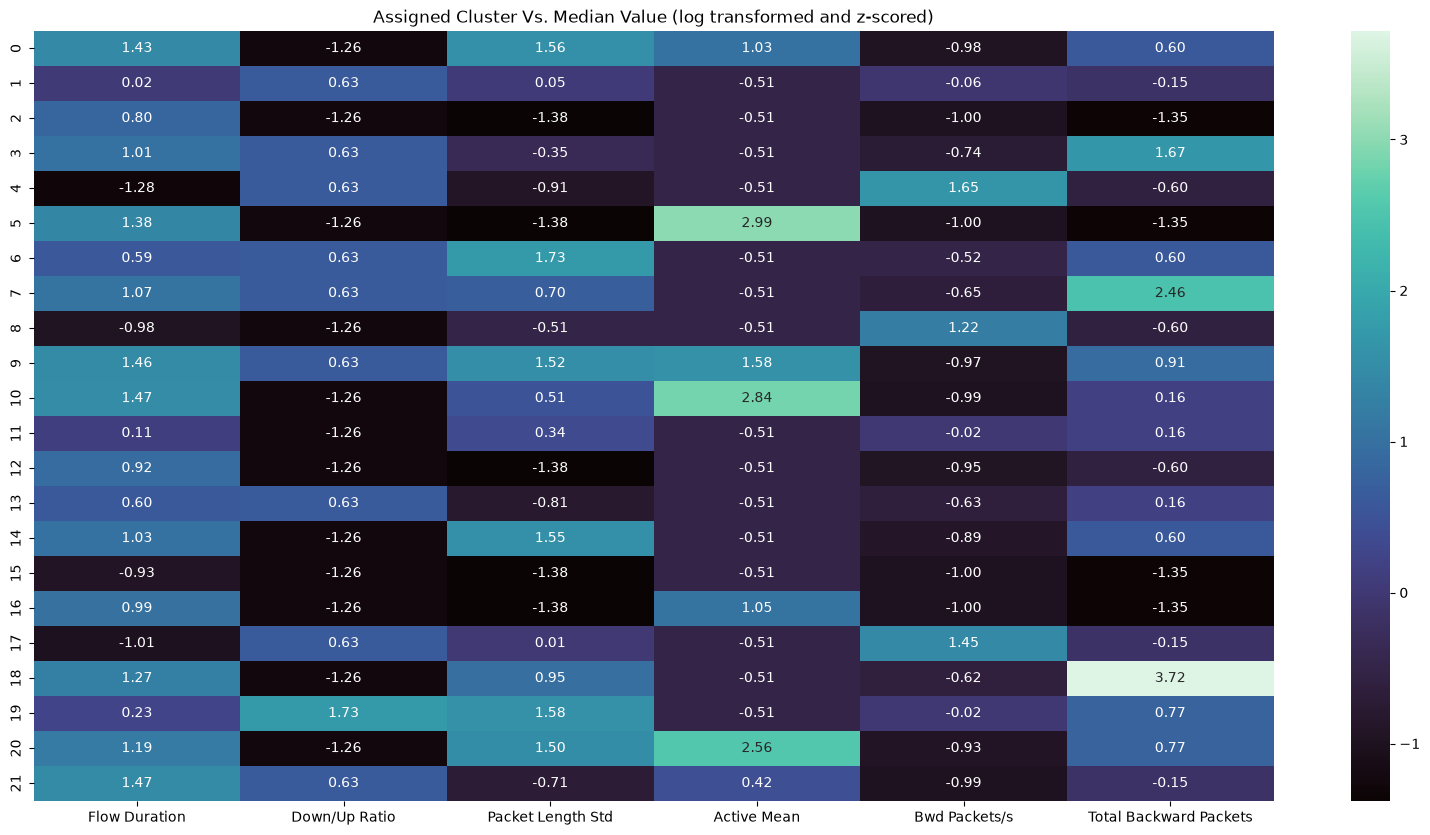

In [42]:
balanced_df = balance_df(reduced_cols_clust_df)
if balance_df is None:
    print("Balancing the DF failed!!")
else:
    _, _ ,_, clust_ass_labs = perform_clustering_exp(balanced_df,expected_groups,hues_dict,perform_pca=False,n_clust=22,show_pcm_vis=False,show_cross_tab=False)
    balanced_df['ass_clusts'] = clust_ass_labs
    balanced_df = balanced_df.drop(columns=['Label'])
    median_clust_vals = balanced_df.groupby(by='ass_clusts')[['Flow Duration', 'Down/Up Ratio', 'Packet Length Std', 'Active Mean',
       'Bwd Packets/s', 'Total Backward Packets']].agg('median')

    plt.figure(figsize=(20, 10))
    sns.heatmap(data=median_clust_vals,annot=True,fmt='.2f',cmap="mako")
    plt.title("Assigned Cluster Vs. Median Value (log transformed and z-scored)")
    plt.ylabel("")
    plt.show()
    

In [68]:
for col in median_clust_vals.columns:
    print(f"{col} {len(median_clust_vals[col].unique())}")

Flow Duration 22
Down/Up Ratio 3
Packet Length Std 18
Active Mean 8
Bwd Packets/s 19
Total Backward Packets 10


In [64]:
# Proving that the original transformation process maps only a few down up ratio value back onto the distinction used in clustering.
test_trans_df = cleanDf[behav_cols]


test_trans_df = np.log10(1 + test_trans_df.clip(lower=0))
test_trans_df = (test_trans_df - test_trans_df.mean()) / test_trans_df.std(ddof=0).replace(0, 1)

test_trans_df['Orig Down/Up'] = cleanDf['Down/Up Ratio']

display(cleanDf.groupby(by='Down/Up Ratio')['Down/Up Ratio'].agg(['count']).sort_values(by="count",ascending=False).head(3))
display(test_trans_df[test_trans_df['Orig Down/Up'] == 1][['Orig Down/Up','Down/Up Ratio']].head(1).reset_index(drop=True))
display(test_trans_df[test_trans_df['Orig Down/Up'] == 0][['Orig Down/Up','Down/Up Ratio']].head(1).reset_index(drop=True))
display(test_trans_df[test_trans_df['Orig Down/Up'] == 2][['Orig Down/Up','Down/Up Ratio']].head(1).reset_index(drop=True))

,count
Down/Up Ratio,
1,1540651
0,904659
2,48449


,Orig Down/Up,Down/Up Ratio
0,1,0.626957


,Orig Down/Up,Down/Up Ratio
0,0,-1.262621


,Orig Down/Up,Down/Up Ratio
0,2,1.732289


In [65]:
# Proving that the original transformation process maps traceably back to original values.
test_trans_df = cleanDf[behav_cols]


test_trans_df = np.log10(1 + test_trans_df.clip(lower=0))
test_trans_df = (test_trans_df - test_trans_df.mean()) / test_trans_df.std(ddof=0).replace(0, 1)

test_trans_df['Orig Active Mean'] = cleanDf['Active Mean']

display(cleanDf.groupby(by='Active Mean')['Active Mean'].agg(['count']).sort_values(by="count",ascending=False).head(3))
display(test_trans_df[test_trans_df['Orig Active Mean'] == 0.0][['Orig Active Mean','Active Mean']].head(1).reset_index(drop=True))
display(test_trans_df[test_trans_df['Orig Active Mean'] == 4.0][['Orig Active Mean','Active Mean']].head(1).reset_index(drop=True))
display(test_trans_df[test_trans_df['Orig Active Mean'] == 5.0][['Orig Active Mean','Active Mean']].head(1).reset_index(drop=True))

,count
Active Mean,
0.0,1961853
4.0,7265
5.0,6859


,Orig Active Mean,Active Mean
0,0.0,-0.505268


,Orig Active Mean,Active Mean
0,4.0,-0.148149


,Orig Active Mean,Active Mean
0,5.0,-0.107693


In [67]:
for col in median_clust_vals.columns:
    print(f"{col} {len(median_clust_vals[col].unique())}")

Flow Duration 22
Down/Up Ratio 3
Packet Length Std 18
Active Mean 8
Bwd Packets/s 19
Total Backward Packets 10


So from the heatmap above, there are a few main takeaways: first, especially for the Down/Up Ratio column, many of the clusters share an identical median normalized value, which maps directly to a frequently occurring non-normalized value. For Down/Up Ratio, the second most frequently occurring value is 0, which maps directly to the normalized -1.26. The Active Mean column is similar, with the most frequently occurring value being 0.0, which maps to the -.51 median value that most clusters have. Clusters like 5 and 16 are different only in their Flow Duration and Active Mean median values. Flow Duration possesses the largest number of distinct median cluster values. So overall, many clusters are very similar in their typical medians, except for a few features being examined in this heatmap.

# Conclusion

So centering back on the original research question:

***Relationship / pattern\
Do the four behavioral groups seen in the exploratory analysis hold up when individual flows are clustered, and are the overlapping pairs (Web Attack – Brute Force vs. XSS; Bot vs. BENIGN) separable at the flow level at all?***


For the first part of the question, whether the four behavioral groups seen in EDA hold up when individual flows are clustered. Partially, with notable exceptions; in the first experiment with unbalanced classes, the ARI was only $0.058$. When we then balanced the classes, we improved our ARI score to $0.227$. So, between unbalanced and balanced classes, our ARI always stayed low, meaning imperfect alignment with the original hypothesized groups. However, we did also observe many classes that did occur in the same clusters as expected. One notable exception; with our optimal k=22 Sql Injection had $38%$ of records in cluster 4 and $38%$ in cluster 6, and PortScan had $98%$ of records in cluster 4. So we have classes like Sql Injection that do not fit neatly into one cluster and occur with originally unexpected classes in some of its points. So while our original grouping does tell part of the story, it does not tell the whole story.

For the flow-level separability, the answer is also no. For example, Web Attack - Brute force in our k = 22 experiment $83%$ of Brute Force records are in cluster 12 and $93%$ of XSS records are in cluster 12. For Bot and BENIGN, BENIGN has $11%$ of points in cluster 4, and Bot has $37%$ of its points in cluster 4. Bot also has $36%$ of its points in cluster 11 and BENIGN has $6%$ of its points in the same cluster. So Bot and BENIGN overlap in clusters 4 and 11 (both are in cluster 13 also). Also, BENIGN traffic is incredibly dispersed between many of the clusters, even in the balanced classes. Furthermore, many features share a repeating median value across clusters. Now, while k-means was unable to separate every attack category in a super clean manner, that does not mean another method couldn't achieve this. Although same classes being dispersed between different clusters might suggest that there is likely not a one size fits all signature for every attack class.